# Trace Pipeline

From exploring existing options, including the feasability tracker, there are a few key things to note.

1. No existing software cleanly handles rupture events
    - Claude seems to think we could detect rupture events from the output of Tierpsy Tracker (no guarentees)
2. No existing software integrates all aspects of the analysis we need
    - Tierpsy: is ideal for basic worm data: size, shape, e.t.c
    - celeST: an existing software suite that analyzes swimming behavior in C. elegans, and seems to be the best match for our application
        - native matlab application, will be controlled as a subprocess in python
    - wrMTrack/SwimR: tracks multiple small organisms in crawling or swimming environemnts, but missing significant detail in worm analysis
3. Building a custom solution seems doable from my perspective, but it's hard to determine how hard this would actually be

From reading (and to be transparent LLM suggestions), it seems like the best solution is to utilize existing software both as a gold standard to evaluate the custom pipelines performance, as well as putting us on track to have a working solution of SOME sort as soon as possible. The other benefit of this approach is that it would cleanly seperate work into a few key categories, and would be easy to distribute tasks between us. The scope I think we should also determine together, because while I think it would be cool to embark on building our own tool in addition to using tierpsy and celeST / other existing solutions, it also likely means a lot more time for anyone involved in those parts of the project. 

## Suggested Approach

I just want to have this written down, that this is my suggested approach. I'm aware I can get over excited sometimes with school so I just want to say I'm totally open to feedback. I think personally that the best approach is basically to process the video in parrellel using tierpsy, celeST, and our custom pipeline.

![Pipeline Diagram](trace_pipeline_overview.png)

In [ ]:
input_video = ''

## Tierpsy Tracker
Run the input video through the tierpsy tracker pipeline.

Calculates general worm metrics, but not complete for analyzing swimming behavior or rupture events.

- Bend Count / Kinks: The literal count of curvature peaks (bends) visible across the body spline at any frame.
- Curvature (Head, Midbody, Tail): Evaluates the absolute angular bending degrees across specific body segments.
- Eigenworms (Postural Modes): Low-dimensional representations of the worm's complex posture mapped against standard behavioral component templates.
- Coiling / Foraging Events: Identifies complex self-intersecting loops (coils) or rapid micro-movements localized to the head (foraging).
- Forward / Backward Motility: Tracks dedicated forward or reversal locomotive bursts based on actual wave propagation vectors.
- Segmental Speed: Independently tracks individual velocities for the head, midbody, and tail (e.g., mean tail speed versus head speed).
- Angular Velocity: Measures the rate at which the animal changes its directional path or turns its body axes over time.
- Track Length: The precise path measurement spanning directly from the tip of the head down to the tail tip.
- Width Profiles: Computes the width of the animal across various body coordinate slices.
- Eccentricity: Evaluates the circularity or overall elongation of the worm's contour footprint within the video area.
- Centroid Trajectories (coord_x, coord_y): Continuous standard X and Y coordinate tracking of the worm's center of mass.
- Tail-to-Head Orientation: The spatial direction vector showing where the head is pointing relative to the frame grid, useful for navigation or chemotaxis assays.

POTENTIAL: Claude believes that we can extract rupture event detection using a script that analyzes Tieprsy's output

In [ ]:
# TODO 

### Detect Rupture Events from HDF5 File (May Not Work)

In [ ]:
# TODO

## CeleST
Run the input video through the CeleST (NOTE: MATLAB NATIVE) pipeline.

Calculates swimming behavior metrics, but lacks rupture event detection and general worm metrics.

- Wave Initiation Rate: The frequency at which locomotion waves are generated at the head or tail.
- Body Wave Number: The number of distinct waves present along the worm's body length at any single moment
- Asymmetry: The bias or imbalance in the worm’s bending toward one side versus the other
- Stretch: The maximum amplitude or physical depth of the body bends during a swim stroke.
- Attenuation: The degree to which the amplitude of the swim wave decreases as it travels down the body.
- Reverse Swimming: The frequency or propensity of the worm to propagate waves in reverse (swimming backward)
- Curling: The frequency or duration of the worm coiling tightly into an overlapping shape.
- Travel Speed: The actual distance covered by the worm's center of mass over time.
- Brush Stroke: The physical area swept or covered by the worm's body shape during a single complete stroke cycle.
- Activity Index: An overarching metric combining proxy data for the velocity, force, and overall vigor of the swim behavior.

In [ ]:
# TODO

## Custom Pipeline
Make the project look more impressive (if when have more time)

### Video Loader (Done)

In [5]:
import cv2
import numpy as np
from typing import Optional

# Load MJPG videos frame by frame as NumPy arrays, in grayscale or RGB
class MJPGVideoLoader:

    def __init__(self, path, mode='gray'):
        self.path = path
        self.video_stream = cv2.VideoCapture(str(self.path))
        if not self.video_stream.isOpened():
            raise IOError(f"Cannot open video: {self.path}")

        self.mode = mode if mode in ('gray', 'rgb') else 'gray'

    @property
    def fps(self):
        return self.video_stream.get(cv2.CAP_PROP_FPS)

    @property
    def frame_size(self):
        return (int(self.video_stream.get(cv2.CAP_PROP_FRAME_WIDTH)),
                int(self.video_stream.get(cv2.CAP_PROP_FRAME_HEIGHT)))

    def next_frame(self) -> Optional[np.ndarray]:
        ret, frame = self.video_stream.read()
        if not ret:
            print("Stream ended, or otherwise failed to read frame.")
            return None

        if self.mode == 'gray':
            # Convert the image to greyscale
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        elif self.mode == 'rgb':
            # Convert the image to rgb
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        return frame

    def __del__(self):
        self.video_stream.release()

### Preprocessing (Done)

In [ ]:
import numpy as np
from PIL import Image, ImageDraw
from scipy import ndimage as ndi
from skimage import filters, morphology, measure
import os
from __future__ import annotations
import cv2
import networkx as nx
from dataclasses import dataclass, field
from scipy import ndimage as ndi
from scipy.interpolate import interp1d
from skimage.morphology import skeletonize
from skimage.measure import label, regionprops
from typing import Optional

# frames is (number of frames, W, H)
def median_sample_frames(frames: np.ndarray, n_sample: int = 100) -> np.ndarray:
    number_of_frames = frames.shape[0]
    idx = np.linspace(0, number_of_frames - 1, min(n_sample, number_of_frames)).astype(int) # Generate the range of indicies to sample over
    return np.median(frames[idx], axis=0)

# Filter the image against a reference background image, optionally taking in the center of mass of the last location of the worm to compare against the current center of mass
def filter_foreground(
    frame: np.ndarray,
    background: np.ndarray,
    min_area_px: float,
    max_area_px: float,
    prev_centroid: Optional[tuple] = None,
) -> Optional[dict]:
    # Take the difference of the frame and the background, then masking anything below zero in that difference
    diff = cv2.absdiff(frame.astype(np.uint8), background.astype(np.uint8))
    _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = mask.astype(bool) 
    labeled = label(mask)

    # Find every connected region remaining that fit the area requirements
    props = [p for p in regionprops(labeled) if min_area_px <= p.area <= max_area_px]
    # Otherwise fail
    if not props: return None

    # If this is used to analyze worms between frames...
    if prev_centroid is not None:
        # Get the corresponding connected component for the last time step
        prev = np.array(prev_centroid)
        chosen = min(props, key=lambda p: np.linalg.norm(np.array(p.centroid) - prev))
    # Otherwise it'll 'choose' the largest connected component
    else:
        chosen = max(props, key=lambda p: p.area)

    component_mask = labeled == chosen.label
    # Find contours along the worm 
    contour, _ = cv2.findContours(component_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    # Interpolate along the skeleton so there's less data points
    perimeter_px = cv2.arcLength(contour[0], closed=True) if contour else np.nan

    return {
        "mask": component_mask,
        "area_px": float(chosen.area),
        "perimeter_px": float(perimeter_px),
        "centroid": chosen.centroid,  # (row, col)
        "n_components": len(props),
    }



### Test 

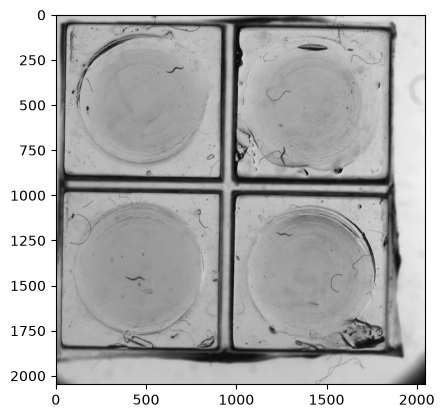

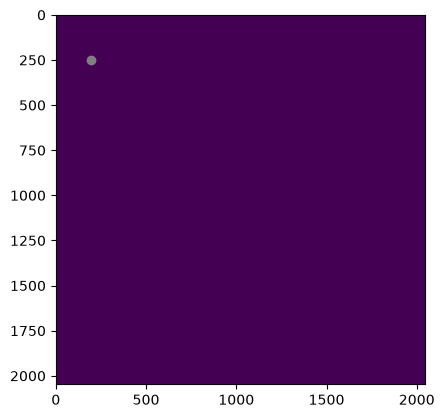

In [65]:
MIX_AREA_PX = 10
MAX_AREA_PX = 100

import numpy as np
import matplotlib.pyplot as plt





def pipeline_photo(frame: np.ndarray, background: np.ndarray) -> np.ndarray:
    res = filter_foreground(frame, background, MIX_AREA_PX, MAX_AREA_PX)
    return res
    

def pipeline_video(frame: np.ndarray, background: np.ndarray) -> np.ndarray:

    # Find the centroid on the first frame
    res = filter_foreground(frame, background, MIX_AREA_PX, MAX_AREA_PX)
    centroid = res["centroid"]

    # While there are remaining frames...
    # Continously track centroid changes I guess
    

i_video = 'data/WORM_MOTEL/RawVideos/WORM_MOTEL.mjpg'
load = MJPGVideoLoader(i_video)
frame0 = load.next_frame() 

plt.imshow(frame0, cmap='gray') # Remove cmap='gray' if your array is RGB
plt.show()

frame0 = pipeline_photo(frame0, np.zeros(frame0.shape))
plt.imshow(frame0['mask'])
plt.scatter(frame0['centroid'][1], frame0['centroid'][0], color='gray')

plt.show()


    

## Synthesis

Combine the output data from each sub-pipeline into one output (One set of data, for each moment time, for each worm), subject to Dr. Hueng's needs basically.

In [ ]:
# TODO

## Plots

Visually display output data for each worm, subject to Dr. Hueng's needs basically.

In [ ]:
# TODO